Loading data...


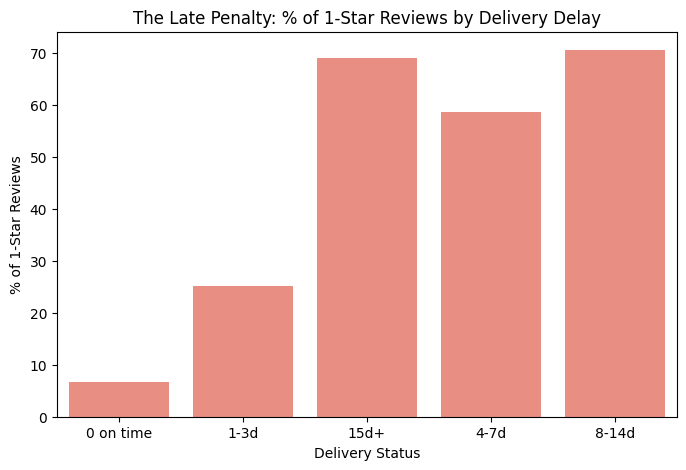

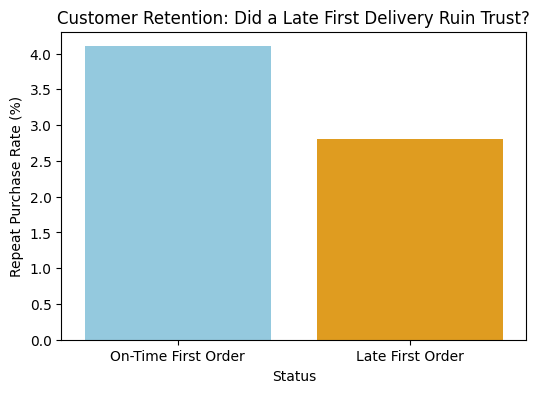

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the raw data (make sure your raw folder has these)
print("Loading data...")
orders = pd.read_csv('raw/olist_orders_dataset.csv')
reviews = pd.read_csv('raw/olist_order_reviews_dataset.csv')
customers = pd.read_csv('raw/olist_customers_dataset.csv')

# 2. Clean up the dates and filter to delivered orders only
orders['delivered_date'] = pd.to_datetime(orders['order_delivered_customer_date']).dt.normalize()
orders['estimated_date'] = pd.to_datetime(orders['order_estimated_delivery_date']).dt.normalize()
orders['purchase_date'] = pd.to_datetime(orders['order_purchase_timestamp']) 

delivered = orders[orders['order_status'] == 'delivered'].dropna(subset=['delivered_date']).copy()

# Calculate how many calendar days late an order is
delivered['days_late'] = (delivered['delivered_date'] - delivered['estimated_date']).dt.days

def bucket_lateness(days):
    if days <= 0: return '0 on time'
    elif days <= 3: return '1-3d'
    elif days <= 7: return '4-7d'
    elif days <= 14: return '8-14d'
    else: return '15d+'

delivered['late_bucket'] = delivered['days_late'].apply(bucket_lateness)

# --- ANALYSIS 1: REVIEWS VS LATENESS ---
# Dedup reviews (keep the latest one per order)
reviews_sorted = reviews.sort_values(['order_id', 'review_answer_timestamp'], ascending=[True, False])
latest_reviews = reviews_sorted.drop_duplicates(subset=['order_id'], keep='first')

# Merge deliveries with reviews
merged = delivered.merge(latest_reviews, on='order_id', how='inner')
merged['is_1_star'] = (merged['review_score'] == 1).astype(int)

# Aggregate severity metrics
severity = merged.groupby('late_bucket').agg(
    orders=('order_id', 'count'),
    avg_score=('review_score', 'mean'),
    pct_1_star=('is_1_star', 'mean')
).reset_index()

severity['pct_1_star'] = (severity['pct_1_star'] * 100).round(1)
severity['avg_score'] = severity['avg_score'].round(2)

# Plot 1: The severity drop-off

plt.figure(figsize=(8, 5))
bucket_order = ['0 on time', '1-3d', '4-7d', '8-14d', '15d+']
sns.barplot(data=severity, x='late_bucket', y='pct_1_star', color='salmon', order=bucket_order)
plt.title('% of 1-Star Reviews by Days Late')
plt.ylabel('% of 1-Star Reviews')
plt.xlabel('Delivery Status')
plt.show()

# --- ANALYSIS 2: CUSTOMER RETENTION ---
# Did late first deliveries ruin repeat purchases?
cust_orders = delivered.merge(customers[['customer_id', 'customer_unique_id']], on='customer_id')

# Find the very first order for every customer
first_orders = cust_orders.sort_values('purchase_date').drop_duplicates('customer_unique_id', keep='first')

# Only look at cohorts before Feb 2018 so they actually have time to reorder
first_orders_pre_feb = first_orders[first_orders['purchase_date'] < '2018-02-01'].copy()

# Find customers who ordered > 1 time globally
order_counts = cust_orders.groupby('customer_unique_id').size()
repeat_customers = order_counts[order_counts > 1].index

first_orders_pre_feb['did_reorder'] = first_orders_pre_feb['customer_unique_id'].isin(repeat_customers)
first_orders_pre_feb['was_late'] = first_orders_pre_feb['days_late'] > 0

# Calculate retention rate
retention = first_orders_pre_feb.groupby('was_late')['did_reorder'].agg(['count', 'mean']).reset_index()
retention['mean'] = (retention['mean'] * 100).round(1)
retention['Status'] = retention['was_late'].map({False: 'On-Time First Order', True: 'Late First Order'})

# Plot 2: Retention Visual
plt.figure(figsize=(6, 4))
sns.barplot(data=retention, x='Status', y='mean', hue='Status', legend=False, palette=['skyblue', 'orange'])
plt.title('Repeat Purchase Rate by First-Order Delivery')
plt.ylabel('Repeat Purchase Rate (%)')
plt.show()

In [8]:
# --- ANALYSIS 3: WHERE ARE ORDERS LATE, AND HOW MUCH MONEY IS INVOLVED? ---
items = pd.read_csv('raw/olist_order_items_dataset.csv')
sellers = pd.read_csv('raw/olist_sellers_dataset.csv')

delivered['was_late'] = delivered['days_late'] > 0
d = delivered.merge(customers[['customer_id', 'customer_state']], on='customer_id')

# Late rate by customer state (with order counts so small states aren't over-read)
by_state = d.groupby('customer_state')['was_late'].agg(orders='count', late_rate='mean')
by_state['late_rate'] = (by_state['late_rate'] * 100).round(1)
print(by_state.sort_values('late_rate', ascending=False).head(5))

# Same-state vs cross-state: use the first seller listed on each order
first_seller = items.sort_values('order_item_id').drop_duplicates('order_id')[['order_id', 'seller_id']]
d = d.merge(first_seller, on='order_id').merge(sellers[['seller_id', 'seller_state']], on='seller_id')
d['cross_state'] = d['seller_state'] != d['customer_state']
print(d.groupby('cross_state')['was_late'].agg(orders='count', late_rate='mean'))

# Sales value tied up in late orders (price only, no freight)
order_value = items.groupby('order_id')['price'].sum().rename('order_value').reset_index()
d = d.merge(order_value, on='order_id')
late_value = d.loc[d['was_late'], 'order_value'].sum()
print(f"\nLate orders: R${late_value:,.0f} of R${d['order_value'].sum():,.0f} delivered sales "
      f"({late_value / d['order_value'].sum():.1%})")

                orders  late_rate
customer_state                   
AL                 397       21.4
MA                 717       17.4
SE                 335       15.2
PI                 476       13.9
CE                1279       13.8
             orders  late_rate
cross_state                   
False         34701   0.045042
True          61769   0.080477

Late orders: R$985,924 of R$13,220,249 delivered sales (7.5%)
